# LangGraph Graph API

LangGraph Graph API는 노드(nodes)와 엣지(edges)로 구성된 상태 기반 워크플로우를 정의하는 시스템입니다.

## 주요 구성 요소

- **State**: 그래프 실행 중 데이터를 저장하는 상태 객체
- **Nodes**: 실제 작업을 수행하는 함수들
- **Edges**: 노드 간의 연결과 실행 흐름을 정의

## 실행 모델

LangGraph는 Google의 Pregel 시스템 기반의 super-step 방식으로 동작합니다:
- 각 super-step에서 하나 이상의 노드를 실행
- 동일 단계의 노드들은 병렬 처리 가능
- 모든 노드 실행 완료 시 그래프 종료

## 환경 설정

LangGraph를 사용하기 위해 필요한 환경 변수와 로깅을 설정합니다. `.env` 파일에 API 키를 저장하고, LangSmith를 통해 실행 과정을 추적할 수 있습니다.

아래 코드는 환경 변수를 로드하고 LangSmith 프로젝트를 설정합니다.

In [1]:
from dotenv import load_dotenv
from langchain_teddynote import logging

# 환경 변수 로드
load_dotenv(override=True)
# 추적을 위한 프로젝트 이름 설정
logging.langsmith("LangChain-V1-Tutorial")

LangSmith 추적을 시작합니다.
[프로젝트명]
LangChain-V1-Tutorial


---

## 그래프 기본 개념

### 그래프 구조

LangGraph의 그래프는 다음 3가지 핵심 구성요소로 이루어집니다:

**State (상태)**
- 그래프 실행 중 데이터를 저장하는 객체
- 노드 간 데이터 전달 및 공유에 사용

**Nodes (노드)**
- 실제 작업을 수행하는 함수
- State를 입력받아 처리 후 업데이트된 State 반환

**Edges (엣지)**
- 노드 간 실행 흐름을 정의
- 다음 실행할 노드를 결정

### 실행 방식

- **Super-step**: 한 번에 하나의 작업 단계 실행
- **병렬 처리**: 동일 단계의 여러 노드를 동시 실행 가능
- **순차 기록**: 각 단계의 결과를 순서대로 기록

In [2]:
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict


# 간단한 그래프 예제
class SimpleState(TypedDict):
    """단일 필드를 가진 간단한 상태"""

    message: str


# StateGraph 생성
graph_builder = StateGraph(SimpleState)


# 노드 함수 정의
def processor(state: SimpleState):
    """상태의 메시지를 처리하는 노드 함수"""
    # 노드는 현재 상태를 입력으로 받고 업데이트를 반환
    return {"message": state["message"] + " - processed"}


# 노드 추가
graph_builder.add_node("processor", processor)

# 엣지 추가 (진입점과 종료점)
graph_builder.add_edge(START, "processor")
graph_builder.add_edge("processor", END)

# 그래프 컴파일 - 필수!
graph = graph_builder.compile()

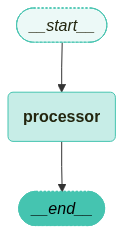

In [3]:
from langchain_teddynote.graphs import visualize_graph

visualize_graph(graph)

In [4]:
# 그래프 실행
result = graph.invoke({"message": "Hello LangGraph"})
print(f"결과: {result}")

결과: {'message': 'Hello LangGraph - processed'}


### 그래프 컴파일

그래프는 실행 전에 컴파일 과정을 거쳐야 합니다.

**컴파일 과정**

1. **구조 검증**: 노드 연결 및 실행 경로 유효성 확인
2. **설정 적용**: checkpointer, interrupt 등의 옵션 적용
3. **실행 객체 생성**: 최적화된 실행 가능 객체 생성

**컴파일 옵션**

| 옵션 | 설명 |
|------|------|
| `checkpointer` | 그래프 실행 중 상태 저장 |
| `interrupt_before` | 특정 노드 실행 전 일시정지 |
| `interrupt_after` | 특정 노드 실행 후 일시정지 |

In [5]:
from langgraph.checkpoint.memory import InMemorySaver

# 체크포인터와 함께 컴파일
memory = InMemorySaver()

graph_with_memory = graph_builder.compile(
    checkpointer=memory,  # 상태 저장을 위한 체크포인터
    # interrupt_before=["processor"],  # 특정 노드 전에 중단 (디버깅용)
    # interrupt_after=["processor"],   # 특정 노드 후에 중단
)

print("체크포인터가 있는 그래프 컴파일 완료!")

체크포인터가 있는 그래프 컴파일 완료!


---

## State 심화

### State 개념

State는 그래프의 데이터 저장소로, 노드 간 데이터 전달 및 공유에 사용됩니다.

### State 정의 방법

**1. TypedDict 방식 (권장)**
```python
class MyState(TypedDict):
    name: str
    count: int
```
- 장점: 간결, 빠른 성능
- 단점: 기본값 설정 불편

**2. Dataclass 방식**
```python
@dataclass
class MyState:
    name: str = "기본값"
    count: int = 0
```
- 장점: 기본값 설정 용이
- 단점: TypedDict보다 오버헤드 존재

**3. Pydantic 방식**
```python
class MyState(BaseModel):
    name: str = "기본값"
    count: int = 0
```
- 장점: 데이터 유효성 검증
- 단점: 가장 무거움

In [6]:
from typing import Annotated, List
from dataclasses import dataclass, field
from pydantic import BaseModel


# 방법 1: TypedDict (가장 일반적, 성능 우수)
class TypedDictState(TypedDict):
    """TypedDict를 사용한 상태 정의"""

    count: int
    items: List[str]


# 방법 2: dataclass (기본값 지원)
@dataclass
class DataclassState:
    """기본값을 지원하는 dataclass 상태 정의"""

    count: int = 0
    items: List[str] = field(default_factory=list)


# 방법 3: Pydantic (재귀적 검증, 성능은 떨어짐)
class PydanticState(BaseModel):
    """데이터 검증을 위한 Pydantic 상태 정의"""

    count: int = 0
    items: List[str] = []


print("세 가지 방식의 State 스키마 정의 완료!")

세 가지 방식의 State 스키마 정의 완료!


### Reducers

Reducer는 State 업데이트 시 새 값과 기존 값을 병합하는 규칙을 정의합니다.

**Reducer 종류**

| Reducer | 동작 | 사용 예시 |
|---------|------|-----------|
| 기본 (None) | 새 값으로 덮어쓰기 | 설정값, 현재 상태 |
| `add` | 기존 값에 추가 | 메시지 목록, 로그 |
| 커스텀 함수 | 사용자 정의 로직 | 최대값 유지, 조건부 병합 |

**사용 예시**

```python
from typing import Annotated
from operator import add

class State(TypedDict):
    value: int  # 기본 리듀서: 덮어쓰기
    messages: Annotated[List[str], add]  # add 리듀서: 추가
    max_score: Annotated[int, lambda old, new: max(old, new)]  # 커스텀
```

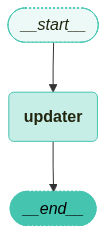

In [7]:
from operator import add


# 기본 리듀서 vs 커스텀 리듀서
class StateWithReducers(TypedDict):
    """커스텀 리듀서가 포함된 상태 정의"""

    # 기본 리듀서: 값을 덮어씀
    current_value: int

    # add 리듀서: 리스트를 연결
    history: Annotated[List[str], add]

    # 커스텀 리듀서: 최대값 유지
    max_value: Annotated[int, lambda x, y: max(x, y)]


# 그래프 생성
builder = StateGraph(StateWithReducers)


def update_values(state: StateWithReducers):
    """상태 값들을 업데이트하는 노드 함수"""
    return {
        "current_value": 10,  # 덮어쓰기
        "history": ["새 항목"],  # 추가
        "max_value": 15,  # 최대값과 비교
    }


builder.add_node("updater", update_values)
builder.add_edge(START, "updater")
builder.add_edge("updater", END)

graph = builder.compile()

# 그래프 시각화
visualize_graph(graph)

In [8]:
# 초기 상태로 실행
initial_state = {"current_value": 5, "history": ["초기 항목"], "max_value": 20}

result = graph.invoke(initial_state)
print("\n리듀서 적용 결과:")
print(f"  current_value: 5 → {result['current_value']} (덮어쓰기)")
print(f"  history: {result['history']} (추가)")
print(f"  max_value: {result['max_value']} (최대값 유지)")


리듀서 적용 결과:
  current_value: 5 → 10 (덮어쓰기)
  history: ['초기 항목', '새 항목'] (추가)
  max_value: 20 (최대값 유지)


### 메시지 처리

대화형 AI 애플리케이션에서 메시지 이력을 관리하는 방법입니다.

**메시지 관리 방법**

**방법 1: add_messages 리듀서**
```python
class ChatState(TypedDict):
    messages: Annotated[List[AnyMessage], add_messages]
```

**방법 2: MessagesState 상속 (권장)**
```python
class ExtendedChatState(MessagesState):
    # messages 필드 자동 포함
    metadata: dict
```

**메시지 타입**

- `HumanMessage`: 사용자 메시지
- `AIMessage`: AI 응답
- `SystemMessage`: 시스템 지시사항
- `ToolMessage`: 도구 실행 결과

In [9]:
from langchain.messages import HumanMessage, AIMessage, AnyMessage
from langgraph.graph.message import add_messages
from langgraph.graph import MessagesState


# 방법 1: add_messages 리듀서 사용
class ChatState(TypedDict):
    """메시지 처리를 위한 상태 정의"""

    messages: Annotated[List[AnyMessage], add_messages]
    metadata: dict


# 방법 2: MessagesState 상속 (더 간단)
class ExtendedChatState(MessagesState):
    """MessagesState를 상속한 확장 상태 정의"""

    # messages 키는 이미 정의되어 있음
    metadata: dict

In [10]:
from langchain_core.runnables import RunnableConfig

# 메시지 처리 예제
builder = StateGraph(ChatState)


def process_chat(state: ChatState):
    """채팅 메시지를 처리하는 노드 함수"""
    # 마지막 메시지 접근
    last_message = state["messages"][-1]

    # 응답 생성
    response = AIMessage(content=f"{last_message.content}")

    return {
        "messages": [response],  # add_messages가 이 Response를 messages 목록에 자동으로 추가
        "metadata": {"processed": True},
    }


builder.add_node("chat", process_chat)
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

memory = InMemorySaver()

chat_graph = builder.compile(checkpointer=memory)

In [11]:
config = RunnableConfig(configurable={"thread_id": "1"})

# 실행
result = chat_graph.invoke(
    {
        "messages": [HumanMessage(content="안녕하세요")],
        "metadata": {},
        "user_info": {"name": "사용자"},
    },
    config=config,
)

print("\n메시지 처리 결과:")
for msg in result["messages"]:
    print(f"  [{msg.__class__.__name__}]: {msg.content}")


메시지 처리 결과:
  [HumanMessage]: 안녕하세요
  [AIMessage]: 안녕하세요


### 다중 스키마

그래프의 입력, 내부 처리, 출력에 각각 다른 스키마를 사용할 수 있습니다.

**스키마 종류**

**InputState**
- 그래프 시작 시 사용자가 제공하는 데이터 형태

**InternalState**
- 그래프 내부 노드들이 사용하는 데이터 구조

**OutputState**
- 그래프 완료 시 반환되는 데이터 형태

**사용 목적**

- **보안**: 내부 처리 로직을 외부에 노출하지 않음
- **단순화**: 사용자는 필요한 정보만 제공
- **유연성**: 내부 구조 변경 시 외부 인터페이스 유지 가능

In [12]:
# 그래프의 입력 스키마
class InputState(TypedDict):
    """입력 스키마 - 사용자가 제공하는 데이터"""

    user_input: str


# 그래프의 출력 스키마
class OutputState(TypedDict):
    """출력 스키마 - 사용자가 받는 데이터"""

    graph_output: str


# 내부에서 사용되는 State
class InternalState(TypedDict):
    """내부 스키마 - 처리를 위한 전체 상태"""

    user_input: str
    internal_state: str


# Private State
class PrivateState(TypedDict):
    """프라이빗 스키마 - 내부 노드 간 통신용"""

    private_state: str

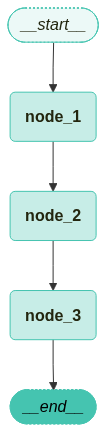

node_1: {'user_input': '사용자 입력'}
node_2: {'user_input': '사용자 입력', 'internal_state': '사용자 입력(node_1 에서 처리됨)'}
node_3: {'private_state': 'PRIVATE: 사용자 입력(node_1 에서 처리됨) (node_2 에서 처리됨)'}

다중 스키마 결과: {'graph_output': '최종 결과: PRIVATE: 사용자 입력(node_1 에서 처리됨) (node_2 에서 처리됨) (node_3 에서 처리됨)'}


In [13]:
# 다중 스키마를 사용하는 그래프
builder = StateGraph(
    InternalState,
    input_schema=InputState,  # 입력 스키마 지정
    output_schema=OutputState,  # 출력 스키마 지정
)


def node_1(state: InputState) -> InternalState:
    """첫 번째 노드 - InputState를 읽고 InternalState에 씀"""
    # InputState를 받지만 InternalState의 키에 쓸 수 있음
    print(f"node_1: {state}")
    return {
        "user_input": state["user_input"],
        "internal_state": state["user_input"] + "(node_1 에서 처리됨)",
    }


def node_2(state: InternalState) -> PrivateState:
    """두 번째 노드 - InternalState를 읽고 PrivateState에 씀"""
    print(f"node_2: {state}")
    # 새로운 state 채널(temp_data) 추가 가능
    return {"private_state": f"PRIVATE: {state['internal_state']} (node_2 에서 처리됨)"}


def node_3(state: PrivateState) -> OutputState:
    """세 번째 노드 - PrivateState를 읽고 OutputState에 씀"""
    print(f"node_3: {state}")
    return {"graph_output": f"최종 결과: {state['private_state']} (node_3 에서 처리됨)"}


# 노드와 엣지 추가
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", "node_3")
builder.add_edge("node_3", END)

multi_schema_graph = builder.compile()

visualize_graph(multi_schema_graph)

# 실행 - 입력은 InputState 형식
result = multi_schema_graph.invoke({"user_input": "사용자 입력"})

# 출력은 OutputState 형식
print(f"\n다중 스키마 결과: {result}")

---

## Nodes 심화

### 노드 개념

노드는 그래프에서 실제 작업을 수행하는 함수입니다.

### 노드 함수 매개변수

노드 함수는 최대 3가지 매개변수를 받을 수 있습니다:

| 매개변수 | 타입 | 설명 |
|----------|------|------|
| `state` | State | 현재 그래프 상태 (필수) |
| `config` | RunnableConfig | 실행 시점 설정 정보 (선택) |
| `store` | BaseStore | 런타임 리소스 접근 (선택) |

**사용 예시**

```python
# state만 사용
def simple_node(state: MyState):
    return {"count": state["count"] + 1}

# state + config 사용
def config_node(state: MyState, config: RunnableConfig):
    user_id = config["configurable"]["user_id"]
    return {"user": user_id}

# 모든 매개변수 사용
def advanced_node(state: MyState, config: RunnableConfig, *, store: BaseStore):
    data = store.get(state["key"])
    return {"data": data}
```

### 실행 시점 값 전달 — 경로 ①: `configurable`

노드는 State 외에도 **실행 시점에만 정해지는 값**을 받을 수 있습니다. 첫 번째 경로는 1주차 메모리(체크포인터)에서 이미 써 본 `config["configurable"]`입니다 — 그때 `thread_id`를 넘겼던 바로 그 자리예요.

```python
config = {
    "configurable": {
        "thread_id": "session_123",   # LangGraph 예약 설정 (체크포인터용)
        "user_id": "user_456",        # 사용자 정의 값도 자유롭게 추가 가능
    }
}
```

노드가 `config` 매개변수를 선언해두면 LangGraph가 이 객체를 넣어주고, 안에서 `config["configurable"].get("키")`로 꺼내 쓰면 됩니다.

자유로운 딕셔너리라 어떤 키든 넣을 수 있지만, 뒤집어 말하면 **키 이름을 잘못 써도 아무도 알려주지 않습니다.** 오타가 나면 그냥 기본값이 조용히 반환될 뿐이에요.

In [14]:
from langchain_core.runnables import RunnableConfig
from langchain.messages import HumanMessage
from langgraph.graph import StateGraph, START, END, MessagesState


class MyState(MessagesState):
    pass


def my_node(state: MyState, config: RunnableConfig):
    """config["configurable"]에서 사용자 정의 설정값을 읽는 노드"""
    runtime_value = config["configurable"].get("runtime_value", "(값 없음)")
    setting_value = config["configurable"].get("setting_value", "(값 없음)")

    print(f"runtime_value: {runtime_value}")
    print(f"setting_value: {setting_value}")
    return {}


builder = StateGraph(MyState)
builder.add_node("my_node", my_node)
builder.add_edge(START, "my_node")
builder.add_edge("my_node", END)
graph = builder.compile()

# 실행 시점에 config["configurable"]로 값 전달
result = graph.invoke(
    {"messages": [HumanMessage(content="안녕하세요")]},
    config={"configurable": {"runtime_value": "I love LangGraph", "setting_value": 123}},
)

runtime_value: I love LangGraph
setting_value: 123


### 경로 ②: `context_schema` — 타입이 지정된 런타임 값 (v1 권장)

LangGraph v1은 사용자 정의 런타임 값을 위한 **전용 경로**를 따로 제공합니다. 세 단계로 연결됩니다:

1. 값의 구조를 `TypedDict`로 선언하고, 그래프에 연결: `StateGraph(..., context_schema=ConfigSchema)`
2. 실행할 때 `invoke(..., context={...})`로 전달 (`config=`가 아니라 `context=`!)
3. 노드에서 `runtime: Runtime[ConfigSchema]` 매개변수로 받아 `runtime.context["키"]`로 읽기

이렇게 하면 IDE 자동완성과 타입 힌트의 도움을 받을 수 있고, "이 그래프는 어떤 런타임 값을 기대하는가"가 코드에 문서처럼 남습니다.

> ⚠️ 단, `TypedDict` 스키마가 **런타임 검증까지 해주지는 않습니다.** 스키마에 없는 키를 `context`로 넘겨도 에러 없이 통과해요. 어디까지나 타입 힌트·자동완성·문서화 장치로 이해하세요. 그리고 `thread_id` 같은 LangGraph 실행 설정은 여전히 경로 ①(`configurable`)로 넘깁니다 — 두 경로는 서로 독립적입니다.

In [15]:
from typing_extensions import TypedDict
from langgraph.runtime import Runtime


# 1) 이 그래프가 기대하는 런타임 값의 구조를 선언
class ConfigSchema(TypedDict):
    my_runtime_value: str
    another_setting: bool


def my_node_v1(state: MyState, runtime: Runtime[ConfigSchema]):
    """runtime.context에서 타입이 지정된 런타임 값을 읽는 노드"""
    print(f"my_runtime_value: {runtime.context['my_runtime_value']}")
    print(f"another_setting: {runtime.context['another_setting']}")
    return {}


# 1) 그래프에 스키마 연결
builder = StateGraph(MyState, context_schema=ConfigSchema)
builder.add_node("my_node_v1", my_node_v1)
builder.add_edge(START, "my_node_v1")
builder.add_edge("my_node_v1", END)
graph = builder.compile()

# 2) config=가 아니라 context= 로 전달 — ConfigSchema에 선언한 키 그대로
result = graph.invoke(
    {"messages": [HumanMessage(content="안녕하세요")]},
    context={"my_runtime_value": "I love LangGraph", "another_setting": True},
)

my_runtime_value: I love LangGraph
another_setting: True


### 두 경로 비교 정리

| | 경로 ① `configurable` | 경로 ② `context` (v1 권장) |
|---|---|---|
| 전달 방법 | `invoke(..., config={"configurable": {...}})` | `invoke(..., context={...})` |
| 노드에서 받기 | `config: RunnableConfig` | `runtime: Runtime[스키마]` |
| 읽기 | `config["configurable"].get("키")` | `runtime.context["키"]` |
| 타입/구조 선언 | 없음 (자유 딕셔너리) | `context_schema=`로 선언 |
| 주 용도 | `thread_id` 등 LangGraph 실행 설정 | `user_id`, 모델 이름 등 사용자 정의 런타임 값 |

### START와 END 노드 (복습)

START와 END는 1주차부터 계속 써 온 **특수 노드**입니다 — 우리가 `add_node`로 만들지 않고, LangGraph가 자동으로 제공합니다. START는 사용자 입력을 첫 노드로 전달하는 진입점, END는 실행을 끝내는 종료점이죠. 여기까지는 아는 내용이니 넘어가고, 한 가지만 새로 기억해 두세요:

**END로 들어오는 엣지는 여러 개일 수 있습니다.** 분기한 갈래들이 저마다 END로 빠지거나, 일부는 다시 앞 노드로 돌아가는(루프) 구조도 가능합니다.

```python
# 기본 플로우
builder.add_edge(START, "first_node")
builder.add_edge("last_node", END)

# 조건부 종료: 검증 통과 시 종료, 실패 시 재시도 루프
builder.add_edge("validation_node", END)
builder.add_edge("retry_node", "first_node")
```

이 "여러 출구 + 루프백" 그림은 바로 뒤의 조건부 엣지 섹션과 Command 섹션에서 실제로 만들어 봅니다.

### 노드 캐싱

노드 캐싱은 계산 결과를 저장하여 재사용하는 최적화 기법입니다.

**CachePolicy 설정**

**ttl (Time To Live)**
```python
ttl=60  # 60초 동안 캐시 유지
ttl=None  # 무제한 캐시 유지
```

**key_func (캐시 키 생성)**
```python
# 기본: 전체 입력을 키로 사용
key_func=None

# 커스텀: 특정 필드만 키로 사용
key_func=lambda state: hash(state["user_id"])
```

**사용 시나리오**

- 계산이 오래 걸리는 작업
- 결과가 자주 반복되는 경우
- 외부 API 호출 비용 절감
- 자주 조회되는 데이터베이스 쿼리

In [16]:
import time
from langgraph.cache.memory import InMemoryCache
from langgraph.types import CachePolicy


class CacheState(TypedDict):
    """캐싱 예제를 위한 상태 정의"""

    x: int
    result: int


builder = StateGraph(CacheState)


def expensive_computation(state: CacheState) -> dict:
    """캐싱이 필요한 무거운 계산 노드"""
    print(f"  무거운 계산 실행 중... (x={state['x']})")
    time.sleep(3)  # 무거운 작업 시뮬레이션
    return {"result": state["x"] * state["x"]}


# 캐시 정책과 함께 노드 추가
builder.add_node(
    "expensive_node",
    expensive_computation,
    cache_policy=CachePolicy(
        ttl=None,  # 캐시 만료 시간(초). None이면 만료 없음
        # key_func=lambda x: hash(x["x"])  # 커스텀 캐시 키 생성 함수
    ),
)

builder.add_edge(START, "expensive_node")
builder.add_edge("expensive_node", END)

# 캐시와 함께 컴파일
cached_graph = builder.compile(cache=InMemoryCache())

print("\n캐싱 테스트:")
print("첫 번째 실행")
start_time = time.time()
result1 = cached_graph.invoke({"x": 10})
print(f"  결과: {result1['result']}, 소요 시간: {time.time() - start_time:.1f}초")

print("\n두 번째 실행")
start_time = time.time()
result2 = cached_graph.invoke({"x": 10})
print(f"  결과: {result2['result']}, 소요 시간: {time.time() - start_time:.1f}초")

print("\n다른 입력으로 실행")
start_time = time.time()
result3 = cached_graph.invoke({"x": 20})
print(f"  결과: {result3['result']}, 소요 시간: {time.time() - start_time:.1f}초")


캐싱 테스트:
첫 번째 실행
  무거운 계산 실행 중... (x=10)
  결과: 100, 소요 시간: 3.0초

두 번째 실행
  결과: 100, 소요 시간: 0.0초

다른 입력으로 실행
  무거운 계산 실행 중... (x=20)
  결과: 400, 소요 시간: 3.0초


In [17]:
print("\n캐싱 테스트:")

result1 = None
%time result1 = cached_graph.invoke({"x": 10})
print(f"  결과: {result1['result']}")


캐싱 테스트:
CPU times: total: 15.6 ms
Wall time: 1.05 ms
  결과: 100


---

## Edges 심화

엣지는 노드 간 실행 흐름을 정의합니다.

### 엣지 종류

**Normal Edges (일반 엣지)**
- 항상 동일한 노드로 이동
- 고정된 실행 순서

**Conditional Edges (조건부 엣지)**
- 상태에 따라 다음 노드 결정
- 동적 라우팅

**Parallel Edges (병렬 엣지)**
- 여러 노드를 동시 실행
- 성능 최적화

### 일반 엣지

일반 엣지는 항상 동일한 경로로 실행됩니다.

```python
builder.add_edge("node_a", "node_b")
```

In [18]:
class EdgeState(TypedDict):
    """엣지 예제를 위한 상태 정의"""

    value: int
    history: List[str]


builder = StateGraph(EdgeState)


# 노드 정의
def node_a(state: EdgeState):
    """노드 A"""
    return {"value": state["value"] + 1, "history": state["history"] + ["A"]}


def node_b(state: EdgeState):
    """노드 B"""
    return {"value": state["value"] * 2, "history": state["history"] + ["B"]}


def node_c(state: EdgeState):
    """노드 C"""
    return {"value": state["value"] - 3, "history": state["history"] + ["C"]}


# 노드 추가
builder.add_node("a", node_a)
builder.add_node("b", node_b)
builder.add_node("c", node_c)

# 일반 엣지 - 항상 A → B → C 순서로 실행
builder.add_edge(START, "a")
builder.add_edge("a", "b")
builder.add_edge("b", "c")
builder.add_edge("c", END)

normal_edge_graph = builder.compile()

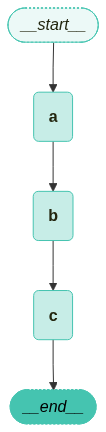

In [19]:
# 그래프 시각화
visualize_graph(normal_edge_graph)

In [20]:
result = normal_edge_graph.invoke({"value": 10, "history": []})
print(f"일반 엣지 결과:")
print(f"  경로: {' → '.join(result['history'])}")
print(f"  최종값: {result['value']}")

일반 엣지 결과:
  경로: A → B → C
  최종값: 19


### 조건부 엣지

조건부 엣지는 상태를 기반으로 다음 노드를 동적으로 결정합니다.

```python
def routing_function(state):
    if state["urgency"] == "high":
        return "intensive_care"
    elif state["urgency"] == "medium":
        return "general_care"
    else:
        return "outpatient_care"

builder.add_conditional_edges(
    "triage_node",
    routing_function
)
```

**사용 시나리오**

- 성공/실패에 따른 분기 처리
- 사용자 타입별 차별화된 처리
- 데이터 크기에 따른 처리 방식 변경
- 오류 타입별 복구 전략

In [21]:
from typing import Literal

builder = StateGraph(EdgeState)

# 노드들 재사용
builder.add_node("a", node_a)
builder.add_node("b", node_b)
builder.add_node("c", node_c)


# 라우팅 함수 정의
def routing_function(state: EdgeState) -> Literal["b", "c"]:
    """상태 값에 따라 라우팅 결정"""
    if state["value"] > 15:
        return "b"  # 큰 값은 B로
    else:
        return "c"  # 작은 값은 C로


# 조건부 엣지 추가
builder.add_edge(START, "a")
builder.add_conditional_edges("a", routing_function)  # 소스 노드  # 라우팅 함수
builder.add_edge("b", END)
builder.add_edge("c", END)

conditional_graph = builder.compile()

# 다른 값으로 테스트
print("조건부 라우팅 테스트:\n")

for initial_value in [10, 20]:
    result = conditional_graph.invoke({"value": initial_value, "history": []})
    print(f"초기값 {initial_value}:")
    print(f"  경로: {' → '.join(result['history'])}")
    print(f"  최종값: {result['value']}\n")

조건부 라우팅 테스트:

초기값 10:
  경로: A → C
  최종값: 8

초기값 20:
  경로: A → B
  최종값: 42



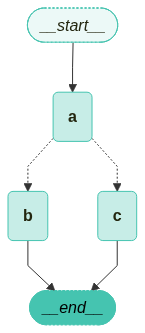

In [22]:
visualize_graph(conditional_graph)

### 매핑 기반 조건부 엣지

복잡한 조건을 매핑 테이블로 정리하여 관리할 수 있습니다.

```python
def categorize(state):
    # 카테고리 분류 로직
    return category_name

category_mapping = {
    "premium": "vip_handler",
    "standard": "normal_handler",
    "basic": "basic_handler"
}

builder.add_conditional_edges(
    "categorizer",
    categorize,
    category_mapping
)
```

**장점**

- 가독성 향상
- 유지보수 용이
- 확장성 개선

In [23]:
# 매핑을 사용한 더 복잡한 라우팅
builder = StateGraph(EdgeState)

builder.add_node(
    "start", lambda s: {"value": s["value"], "history": s["history"] + ["start"]}
)
builder.add_node(
    "process_high",
    lambda s: {"value": s["value"] * 10, "history": s["history"] + ["high"]},
)
builder.add_node(
    "process_medium",
    lambda s: {"value": s["value"] * 5, "history": s["history"] + ["medium"]},
)
builder.add_node(
    "process_low",
    lambda s: {"value": s["value"] * 2, "history": s["history"] + ["low"]},
)


def categorize_value(state: EdgeState) -> str:
    """값을 high/medium/low로 분류"""
    if state["value"] > 100:
        return "high"
    elif state["value"] > 50:
        return "medium"
    else:
        return "low"


# 매핑을 사용한 조건부 엣지
builder.add_edge(START, "start")
builder.add_conditional_edges(
    "start",
    categorize_value,
    {"high": "process_high", "medium": "process_medium", "low": "process_low"},
)

# 모든 처리 노드는 END로
for node in ["process_high", "process_medium", "process_low"]:
    builder.add_edge(node, END)

mapped_graph = builder.compile()

# 테스트
print("매핑 기반 라우팅 테스트:\n")
for value in [30, 75, 150]:
    result = mapped_graph.invoke({"value": value, "history": []})
    print(f"초기값 {value}: {' → '.join(result['history'])}, 결과: {result['value']}")

매핑 기반 라우팅 테스트:

초기값 30: start → low, 결과: 60
초기값 75: start → medium, 결과: 375
초기값 150: start → high, 결과: 1500


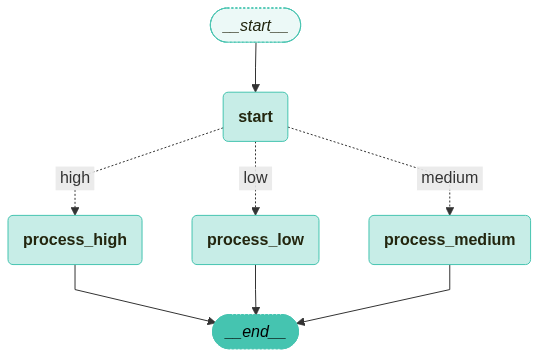

In [24]:
visualize_graph(mapped_graph)

### 병렬 실행

여러 노드를 동시에 실행하여 처리 시간을 단축할 수 있습니다.

**병렬 실행 조건**

하나의 노드에서 여러 노드로 나가는 엣지가 있으면 자동으로 병렬 실행됩니다.

```python
def parallel_routing(state):
    return ["parallel_a", "parallel_b", "parallel_c"]

builder.add_conditional_edges("splitter", parallel_routing)
```

**장점**

- 처리 시간 단축
- 리소스 활용 극대화
- 처리량 향상

**주의사항**

- 작업 간 의존성이 없어야 함
- 공유 리소스 접근 시 동기화 필요
- 실행 순서가 중요한 작업에는 부적합

In [25]:
from typing import List


class ParallelState(TypedDict):
    """병렬 실행을 위한 상태 정의"""

    input: int
    nodes: str
    results: Annotated[List[AnyMessage], add_messages]


builder = StateGraph(ParallelState)


def splitter(state: ParallelState):
    """여러 경로로 분할하는 노드"""
    return {"results": ["분할 완료"]}


def parallel_a(state: ParallelState):
    """병렬 처리 A 노드"""
    print("[Node A]")
    time.sleep(0.5)  # 작업 시뮬레이션
    return {"results": [f"A: {state['input'] * 2}"]}


def parallel_b(state: ParallelState):
    """병렬 처리 B 노드"""
    print("[Node B]")
    time.sleep(1.0)  # 작업 시뮬레이션
    return {"results": [f"B: {state['input'] + 10}"]}


def parallel_c(state: ParallelState):
    """병렬 처리 C 노드"""
    print("[Node C]")
    time.sleep(2.0)  # 작업 시뮬레이션
    return {"results": [f"C: {state['input'] ** 2}"]}


def merger(state: ParallelState):
    """결과 병합 노드"""
    return {"results": ["병합 완료"]}


# 노드 추가
builder.add_node("splitter", splitter)
builder.add_node("parallel_a", parallel_a)
builder.add_node("parallel_b", parallel_b)
builder.add_node("parallel_c", parallel_c)
builder.add_node("merger", merger)


# 병렬 실행을 위한 조건부 엣지
def parallel_routing(state: ParallelState) -> List[str]:
    """병렬 실행을 위해 여러 노드로 라우팅"""

    print(f"[Parallel Routing] {state['nodes']}")

    if state["nodes"].upper() == "A":
        return ["parallel_a"]
    elif state["nodes"].upper() == "B":
        return ["parallel_b"]
    elif state["nodes"].upper() == "C":
        return ["parallel_c"]
    elif state["nodes"].upper() == "AB" or state["nodes"].upper() == "BA":
        return ["parallel_a", "parallel_b"]
    elif state["nodes"].upper() == "AC" or state["nodes"].upper() == "CA":
        return ["parallel_a", "parallel_c"]
    elif state["nodes"].upper() == "BC" or state["nodes"].upper() == "CB":
        return ["parallel_b", "parallel_c"]
    elif state["nodes"].upper() == "ABC":
        return ["parallel_a", "parallel_b", "parallel_c"]


builder.add_edge(START, "splitter")
builder.add_conditional_edges("splitter", parallel_routing)

# 모든 병렬 노드는 merger로
builder.add_edge("parallel_a", "merger")
builder.add_edge("parallel_b", "merger")
builder.add_edge("parallel_c", "merger")
builder.add_edge("merger", END)

parallel_graph = builder.compile()

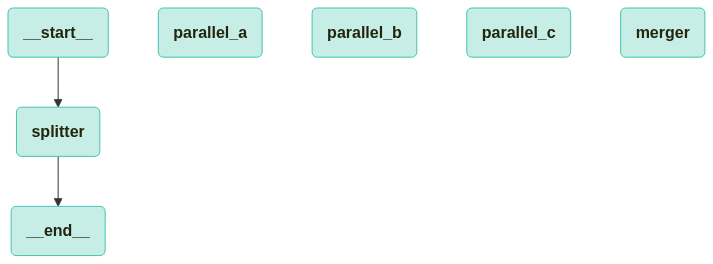

In [26]:
# 그래프 시각화
visualize_graph(parallel_graph, xray=True)

In [28]:
from langchain_teddynote.messages import invoke_graph

start_time = time.time()
invoke_graph(
    parallel_graph, inputs={"input": 3, "nodes": "ca", "results": []}, config=None
)
elapsed = time.time() - start_time

print(f"\n실행 시간: {elapsed:.1f}초 (병렬 실행으로 시간 단축)")

[Parallel Routing] ca

🔄 Node: splitter 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
분할 완료
[Node A]
[Node C]

🔄 Node: parallel_a 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
A: 6

🔄 Node: parallel_c 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
C: 9

🔄 Node: merger 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
병합 완료

실행 시간: 2.0초 (병렬 실행으로 시간 단축)


---

## Send - 동적 라우팅

### Send 개념

지금까지의 조건부 엣지는 "다음에 **어느 노드로 갈지**"만 정했습니다. 그런데 이런 요구가 있다면요? — "주제가 5개 들어오면 농담 생성 노드를 5개 띄우고, 3개 들어오면 3개만." 몇 개가 필요한지 **실행해 봐야 아는** 상황입니다. 설계 시점에 엣지를 고정하는 방식으로는 풀 수 없죠.

`Send`는 라우팅 함수가 문자열 대신 반환하는 특수 객체로, 두 가지를 **동시에** 정합니다:

1. **몇 개를 실행할지** — 반환한 Send 리스트의 길이만큼 대상 노드 인스턴스가 **병렬로** 뜹니다. 개수는 실행 시점의 데이터가 정합니다.
2. **각각 어떤 입력으로** — `Send("노드이름", {...})`의 두 번째 인자가 **그 인스턴스의 state가 됩니다.** 그래프의 공용 State가 아니라, 내가 조립한 맞춤 딕셔너리를 들려 보내는 거예요. 그래서 받는 노드의 타입 힌트도 공용 State가 아닌 **별도의 작은 스키마**로 선언합니다.

```python
def dynamic_router(state):
    # 아이템 개수만큼 Send 생성 → process_item 노드가 그 수만큼 병렬 실행
    return [Send("process_item", {"item": item}) for item in state["items"]]

builder.add_conditional_edges("splitter", dynamic_router, ["process_item"])
# 세 번째 인자가 매핑(dict)이 아니라 '가능한 목적지 목록(list)'인 점에 주목
# — 목적지는 Send 객체 안에 이미 적혀 있으니 변환표가 필요 없습니다
```

흩어진 인스턴스들의 반환값은 공용 State의 **리듀서**(`add`, `add_messages`)가 한곳으로 합칩니다. 이 "작업 분할(Map) → 병렬 처리 → 리듀서로 통합(Reduce)" 조합이 **Map-Reduce 패턴**입니다.

**일반 조건부 엣지 vs Send**

| | 조건부 엣지 (문자열 반환) | Send 반환 |
|---|---|---|
| 정하는 것 | 다음 노드 **하나** | 노드 인스턴스 **개수 + 각각의 입력** |
| 노드가 받는 state | 공용 State | Send에 담아 보낸 맞춤 딕셔너리 |
| 개수 결정 시점 | 그래프 설계 시점 | **실행 시점** (데이터가 정함) |

**사용 시나리오**: 문서 100건을 건별로 요약(대용량 병렬 처리), 입력 크기에 따라 워커 수 조절(동적 스케일링), 배치 처리, 조건을 만족하는 항목만 골라 병렬화(조건부 병렬화)

아래 예제는 이 모든 요소를 담은 농담 생성기입니다 — "3개가 찰 때까지 부족한 만큼만" Send를 뿌리는 자기 교정 루프까지 들어 있어요.

In [29]:
from typing import TypedDict, List, Annotated, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages, AnyMessage
from langgraph.types import Send
from langchain_openai import ChatOpenAI
from langchain.messages import HumanMessage, SystemMessage
import random

# ChatGPT 모델 초기화
llm = ChatOpenAI(model="gpt-5.4-mini", temperature=0.7)


# State 정의
class JokeGeneratorState(TypedDict):
    """농담 생성 상태"""

    jokes: Annotated[List[AnyMessage], add_messages]
    current_subject: str
    attempt_count: int


class SingleJokeState(TypedDict):
    """개별 농담 생성 상태"""

    subject: str
    joke_number: int


# StateGraph 생성
builder = StateGraph(JokeGeneratorState)


def initialize_state(state: JokeGeneratorState) -> dict:
    """초기 상태 설정"""
    subjects = ["프로그래머", "AI", "파이썬", "자바스크립트", "데이터베이스"]
    selected_subject = random.choice(subjects)

    print(f"선택된 주제: {selected_subject}")
    print("=" * 50)

    return {"current_subject": selected_subject, "jokes": [], "attempt_count": 0}


def generate_single_joke(state: SingleJokeState) -> dict:
    """LLM을 사용하여 개별 농담 생성"""
    messages = [
        SystemMessage(
            content="당신은 재미있는 IT 농담을 만드는 코미디언입니다. 짧고 재치있는 농담을 한국어로 만들어주세요."
        ),
        HumanMessage(
            content=f"{state['subject']}에 대한 재미있는 농담을 하나만 만들어주세요. (농담 #{state['joke_number']})"
        ),
    ]

    response = llm.invoke(messages)
    joke = response.content.strip()

    print(f"농담 #{state['joke_number']}: {joke}")

    return {"jokes": [joke]}


def update_attempt_count(state: JokeGeneratorState) -> dict:
    """시도 횟수 업데이트"""
    attempt_count = state.get("attempt_count", 0) + 1
    current_joke_count = len(state.get("jokes", []))

    print(f"\n현재 농담 개수: {current_joke_count}/3")
    print(f"시도 횟수: {attempt_count}")

    return {"attempt_count": attempt_count}


def route_based_on_count(state: JokeGeneratorState) -> List[Send]:
    """농담 개수에 따라 Send로 라우팅"""
    current_joke_count = len(state.get("jokes", []))

    if current_joke_count < 3:
        # 3개 미만이면 부족한 만큼 generate_joke로 Send
        sends = []
        for i in range(current_joke_count + 1, 4):  # 3개까지 생성
            sends.append(
                Send(
                    "generate_joke",
                    {"subject": state["current_subject"], "joke_number": i},
                )
            )
        print(f"{len(sends)}개의 농담을 추가로 생성합니다...")
        return sends
    else:
        # 3개 이상이면 finalize로
        print("농담 3개 생성 완료! 최종 정리 단계로 이동합니다.")
        return [Send("finalize", state)]


def finalize_jokes(state: JokeGeneratorState) -> dict:
    """최종 농담 정리"""
    print("\n" + "=" * 50)
    print(f"최종 농담 컬렉션 ({state['current_subject']} 주제)")
    print("=" * 50)

    jokes = state.get("jokes", [])
    for i, joke in enumerate(jokes, 1):
        print(f"\n농담 {i}: {joke}")

    summary = f"\n\n총 {len(jokes)}개의 농담이 생성되었습니다. (시도 횟수: {state.get('attempt_count', 1)}회)"

    return {"jokes": jokes + [summary]}


# 노드 추가
builder.add_node("initialize", initialize_state)
builder.add_node("generate_joke", generate_single_joke)
builder.add_node("update_count", update_attempt_count)
builder.add_node("finalize", finalize_jokes)

# 엣지 추가
builder.add_edge(START, "initialize")
builder.add_edge("initialize", "update_count")

# update_count 노드 이후 conditional_edges로 Send 처리
builder.add_conditional_edges(
    "update_count",
    route_based_on_count,  # Send 리스트를 반환하는 라우팅 함수
    ["generate_joke", "finalize"],  # 가능한 목적지 노드들
)

# generate_joke 완료 후 다시 update_count로
builder.add_edge("generate_joke", "update_count")

# finalize 후 종료
builder.add_edge("finalize", END)

# 그래프 컴파일
joke_generator = builder.compile()

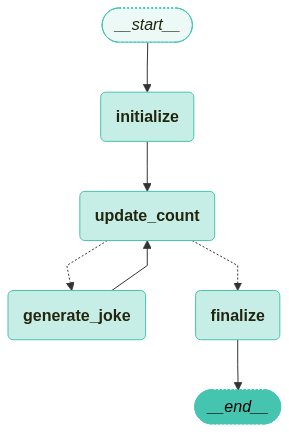

In [30]:
visualize_graph(joke_generator)

In [31]:
from langchain_teddynote.messages import stream_graph

stream_graph(
    joke_generator,
    inputs={"current_subject": "AI", "jokes": [], "attempt_count": 0},
    config=None,
)

선택된 주제: 자바스크립트

현재 농담 개수: 0/3
시도 횟수: 1
3개의 농담을 추가로 생성합니다...

🔄 Node: generate_joke 🔄
- - - - - - - - - - - - - - - - - - - - - - - - - 
자바스크립트가 제일 자신 있는자바 건 뭐스크립게요트는 참 친?  
절해**느요.  
숫슨한 약속이요자도.** 문자도 😄 다농담 #2: 자바스크립트가 제일 자신 있는 건 뭐게요?  
**느슨한 약속이요.** 😄
 받아주는데, 정작 본인은 **무슨 타입인지 매번 바뀌는 사람** 같거든요.농담 #1: 자바스크립트는 참 친절해요.  
숫자도 문자도 다 받아주는데, 정작 본인은 **무슨 타입인지 매번 바뀌는 사람** 같거든요.
자바스크립트가 “약속은 꼭 지킨다”고 해서 믿었는데, 결국 **Promise**만 남기고 사라졌어요.농담 #3: 자바스크립트가 “약속은 꼭 지킨다”고 해서 믿었는데, 결국 **Promise**만 남기고 사라졌어요.

현재 농담 개수: 3/3
시도 횟수: 2
농담 3개 생성 완료! 최종 정리 단계로 이동합니다.

최종 농담 컬렉션 (자바스크립트 주제)

농담 1: content='자바스크립트는 참 친절해요.  \n숫자도 문자도 다 받아주는데, 정작 본인은 **무슨 타입인지 매번 바뀌는 사람** 같거든요.' additional_kwargs={} response_metadata={} id='4d4b40f4-347b-4c00-b7ba-bb7e9214951d'

농담 2: content='자바스크립트가 제일 자신 있는 건 뭐게요?  \n**느슨한 약속이요.** 😄' additional_kwargs={} response_metadata={} id='51374ed0-56b3-443c-9ea9-8db5eb83ef95'

농담 3: content='자바스크립트가 “약속은 꼭 지킨다”고 해서 믿었는데, 결국 **Promise**만 남기고 사라졌어요.' additional_kwargs={} response_metadata={}

---

## Command - 통합 제어

### Command 개념

Command는 상태 업데이트와 제어 흐름을 동시에 처리할 수 있는 객체입니다.

**핵심 기능**

**update** - 상태 업데이트
```python
Command(
    update={
        "score": state["score"] + 10,
        "level": "advanced"
    }
)
```

**goto** - 제어 흐름
```python
Command(
    update={...},
    goto="next_stage"
)
```

**사용 시나리오**

- 상태 업데이트와 라우팅 동시 처리
- 멀티 에이전트 핸드오프
- 복잡한 비즈니스 로직 구현

### Command 활용

Command를 사용하면 상태 업데이트와 제어 흐름을 하나의 객체로 처리할 수 있습니다.

```python
Command(
    update={
        "treatment_status": "완료",
        "next_appointment": "2025-11-15",
        "bill_amount": 50000
    },
    goto="discharge" if recovered else "follow_up"
)
```

In [32]:
from langgraph.types import Command
from typing import Literal
from typing_extensions import TypedDict


class CommandState(TypedDict):
    """Command 예제를 위한 상태 정의"""

    value: int


def my_node(state: CommandState) -> Command[Literal["my_other_node"]]:
    """상태를 업데이트하고 결정을 내리는 노드"""
    return Command(
        # state update
        update={"foo": "bar"},
        # control flow
        goto="my_other_node",
    )

Command를 사용하면 조건부 엣지와 동일한 동적 제어 흐름을 구현할 수 있습니다.

In [33]:
def my_node(state: CommandState) -> Command[Literal["my_other_node"]]:
    if state["foo"] == "bar":
        return Command(update={"foo": "baz"}, goto="my_other_node")

### 상위 그래프로 이동

하위 그래프 내 노드에서 상위 그래프의 다른 노드로 이동하려면 `graph=Command.PARENT`를 지정합니다.

In [34]:
def my_node(state: CommandState) -> Command[Literal["other_subgraph"]]:
    return Command(
        update={"foo": "bar"},
        goto="other_subgraph",  # where `other_subgraph` is a node in the parent graph
        graph=Command.PARENT,
    )

### Command 통합 예제

`Command`를 사용하여 `update`와 `goto`를 동시에 사용하는 예제입니다.

In [35]:
from langgraph.types import Command


class CommandState(TypedDict):
    """Command 예제를 위한 상태 정의"""

    value: int
    message: str
    path: List[str]


builder = StateGraph(CommandState)


# Command를 반환하는 노드
def decision_node(
    state: CommandState,
) -> Command[Literal["success", "failure", "retry"]]:
    """상태를 업데이트하고 결정을 내리는 노드"""
    value = state["value"]

    if value > 100:
        return Command(
            # 상태 업데이트
            update={
                "message": "값이 너무 큽니다",
                "path": state["path"] + ["decision"],
            },
            # 라우팅
            goto="failure",
        )
    elif value > 50:
        return Command(
            update={
                "message": "처리 성공",
                "value": value * 2,
                "path": state["path"] + ["decision"],
            },
            goto="success",
        )
    else:
        return Command(
            update={
                "message": "재시도 필요",
                "value": value + 30,
                "path": state["path"] + ["decision"],
            },
            goto="retry",
        )


def success_node(state: CommandState):
    """성공 처리 노드"""
    return {"message": f"[성공] {state['message']}", "path": state["path"] + ["success"]}


def failure_node(state: CommandState):
    """실패 처리 노드"""
    return {"message": f"[실패] {state['message']}", "path": state["path"] + ["failure"]}


def retry_node(state: CommandState) -> Command[Literal["decision"]]:
    """재시도 처리 노드 - decision으로 되돌아감"""
    return Command(
        update={"message": "재시도 중...", "path": state["path"] + ["retry"]},
        goto="decision",  # 다시 결정 노드로
    )


# 노드 추가
builder.add_node("decision", decision_node)
builder.add_node("success", success_node)
builder.add_node("failure", failure_node)
builder.add_node("retry", retry_node)

# 엣지 추가
builder.add_edge(START, "decision")
builder.add_edge("success", END)
builder.add_edge("failure", END)
# retry는 Command로 decision으로 돌아감

command_graph = builder.compile()

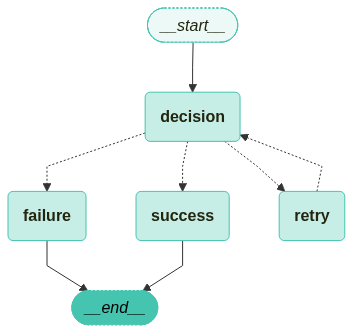

In [36]:
visualize_graph(command_graph)

In [37]:
# 그래프 실행
test_values = [30, 75, 150]
for val in test_values:
    result = command_graph.invoke({"value": val, "message": "", "path": []})
    print(f"초기값 {val}:")
    print(f"  경로: {' → '.join(result['path'])}")
    print(f"  메시지: {result['message']}")
    print(f"  최종값: {result['value']}\n")

초기값 30:
  경로: decision → retry → decision → success
  메시지: [성공] 처리 성공
  최종값: 120

초기값 75:
  경로: decision → success
  메시지: [성공] 처리 성공
  최종값: 150

초기값 150:
  경로: decision → failure
  메시지: [실패] 값이 너무 큽니다
  최종값: 150



### Command vs 조건부 엣지

**Command 사용 시**

- 상태 업데이트와 라우팅을 동시에 수행해야 할 때
- 멀티 에이전트 핸드오프에서 정보 전달이 필요할 때

**조건부 엣지 사용 시**

- 상태 업데이트 없이 라우팅만 필요할 때
- 단순한 분기 로직

아래 예제가 바로 **"조건부 엣지로는 못 짜는 경우"**입니다. 직접 바꿔 보려고 하면 벽에 부딪혀요:

```python
# 조건부 엣지로 시도해 보면...
def route(state) -> str:
    if "코드" in state["task"]:
        return "engineer"   # 갈 곳은 정할 수 있지만...
        # handoff_info를 쓸 방법이 없다! (라우팅 함수는 문자열만 반환할 뿐, 상태를 못 씀)
```

그런데 아래의 `engineer_agent`와 `designer_agent`는 `state["handoff_info"]`를 읽어서 일합니다. 즉 분석가(analyst)가 "어디로 보낼지"와 "받는 쪽이 필요로 하는 인수인계 메모"를 **동시에** 넘겨야 하는 구조 — 이것이 이 상황에서 Command가 필요한 이유입니다.

In [38]:
# 멀티 에이전트 핸드오프 예제
class AgentState(TypedDict):
    """멀티 에이전트 시스템을 위한 상태 정의"""

    task: str
    current_agent: str
    result: str
    handoff_info: dict


builder = StateGraph(AgentState)


def analyst_agent(state: AgentState) -> Command[Literal["engineer", "designer"]]:
    """태스크를 위임하는 분석가 에이전트"""
    task = state["task"]

    if "코드" in task or "구현" in task:
        return Command(
            update={
                "current_agent": "engineer",
                "handoff_info": {
                    "priority": "high",
                    "language": "Python",
                    "analyzed_by": "analyst",
                },
            },
            goto="engineer",
        )
    else:
        return Command(
            update={
                "current_agent": "designer",
                "handoff_info": {"style": "modern", "analyzed_by": "analyst"},
            },
            goto="designer",
        )


def engineer_agent(state: AgentState):
    """엔지니어 에이전트"""
    info = state["handoff_info"]
    return {"result": f"엔지니어가 {info.get('language', 'unknown')}로 구현 완료"}


def designer_agent(state: AgentState):
    """디자이너 에이전트"""
    info = state["handoff_info"]
    return {"result": f"디자이너가 {info.get('style', 'unknown')} 스타일로 디자인 완료"}


# 노드 추가
builder.add_node("analyst", analyst_agent)
builder.add_node("engineer", engineer_agent)
builder.add_node("designer", designer_agent)

# 엣지 추가
builder.add_edge(START, "analyst")
builder.add_edge("engineer", END)
builder.add_edge("designer", END)

agent_graph = builder.compile()

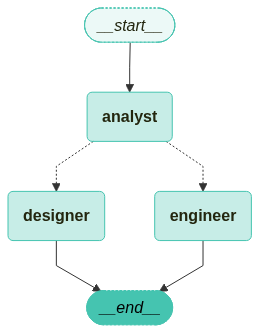

In [39]:
visualize_graph(agent_graph)

In [40]:
# 테스트
print("멀티 에이전트 핸드오프 테스트:\n")

tasks = ["로그인 기능 구현", "홈페이지 디자인"]
for task in tasks:
    result = agent_graph.invoke(
        {"task": task, "current_agent": "analyst", "result": "", "handoff_info": {}}
    )
    print(f"작업: {task}")
    print(f"  담당 에이전트: {result['current_agent']}")
    print(f"  전달 정보: {result['handoff_info']}")
    print(f"  결과: {result['result']}\n")

멀티 에이전트 핸드오프 테스트:

작업: 로그인 기능 구현
  담당 에이전트: engineer
  전달 정보: {'priority': 'high', 'language': 'Python', 'analyzed_by': 'analyst'}
  결과: 엔지니어가 Python로 구현 완료

작업: 홈페이지 디자인
  담당 에이전트: designer
  전달 정보: {'style': 'modern', 'analyzed_by': 'analyst'}
  결과: 디자이너가 modern 스타일로 디자인 완료



---

## 고급 기능

### 재귀 제한 (Recursion Limit)

무한 루프를 방지하기 위해 그래프 실행의 최대 super-step 수를 제한할 수 있습니다.

In [41]:
class LoopState(TypedDict):
    """루프 예제를 위한 상태 정의"""

    counter: int
    history: List[int]


builder = StateGraph(LoopState)


def increment_node(state: LoopState) -> Command[Literal["increment", "end"]]:
    """카운터를 증가시키는 노드"""
    new_counter = state["counter"] + 1

    print(f"new_counter: {new_counter}")

    if new_counter < 10:  # 의도적으로 높은 목표 설정
        return Command(
            update={
                "counter": new_counter,
                "history": state["history"] + [new_counter],
            },
            goto="increment",  # 자기 자신으로 루프
        )
    else:
        return Command(update={"counter": new_counter}, goto="end")


def end_node(state: LoopState):
    """종료 노드"""
    return {"history": state["history"] + [999]}


builder.add_node("increment", increment_node)
builder.add_node("end", end_node)
builder.add_edge(START, "increment")
builder.add_edge("end", END)

loop_graph = builder.compile()

# 재귀 제한 설정
print("재귀 제한 테스트:\n")

try:
    # 재귀 제한 5로 실행
    result = loop_graph.invoke(
        {"counter": 0, "history": []}, config={"recursion_limit": 5}  # 최대 5번만 실행
    )
except Exception as e:
    print(f"에러 발생: {e}")

재귀 제한 테스트:

new_counter: 1
new_counter: 2
new_counter: 3
new_counter: 4
new_counter: 5
에러 발생: Recursion limit of 5 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT


In [42]:
# 충분한 재귀 제한으로 실행
result = loop_graph.invoke(
    {"counter": 0, "history": []}, config={"recursion_limit": 100}
)
print(f"\n성공: counter={result['counter']}, 실행 횟수={len(result['history'])}")

new_counter: 1
new_counter: 2
new_counter: 3
new_counter: 4
new_counter: 5
new_counter: 6
new_counter: 7
new_counter: 8
new_counter: 9
new_counter: 10

성공: counter=10, 실행 횟수=10


---

# 🧩 2주차 퀴즈 ② — Graph API

빈칸(`________`)을 채우고 실행해보세요. 제출 방법은 퀴즈 ①(02-LangGraph-Messages.ipynb)의 안내와 같습니다.

> 💡 이 퀴즈는 **API 키가 필요 없습니다.** 전부 순수 Python 그래프입니다.

### Q1. 리듀서 지정하기

스터디 진행 상황을 관리하는 State를 완성하세요.
`history`는 **기존 리스트에 추가**되고, `best_score`는 **더 큰 값이 유지**되어야 합니다.

In [43]:
from typing import Annotated, List
from typing_extensions import TypedDict
from operator import add
from langgraph.graph import StateGraph, START, END


class QuizState(TypedDict):
    round: int  # 기본 리듀서: 덮어쓰기
    history: Annotated[List[str], add]  # 리스트에 '추가'되는 리듀서
    best_score: Annotated[int, lambda old, new: max(old, new)]  # 최대값 유지


def play_round(state: QuizState):
    return {"round": 2, "history": ["2라운드 완료"], "best_score": 80}


builder = StateGraph(QuizState)
builder.add_node("play", play_round)
builder.add_edge(START, "play")
builder.add_edge("play", END)
graph = builder.compile()

result = graph.invoke({"round": 1, "history": ["1라운드 완료"], "best_score": 95})
print(result)

# ---- 자동 채점 ----
assert result["round"] == 2, "round는 기본 리듀서라 새 값 2로 덮어써야 합니다"
assert result["history"] == [
    "1라운드 완료",
    "2라운드 완료",
], "history는 덮어쓰지 말고 기존 리스트에 추가되어야 합니다"
assert result["best_score"] == 95, "best_score는 더 큰 값(95)이 유지되어야 합니다 (80으로 덮어쓰면 안 돼요)"
print("통과! 🎉")

{'round': 2, 'history': ['1라운드 완료', '2라운드 완료'], 'best_score': 95}
통과! 🎉


### Q2. 매핑 기반 조건부 엣지

값의 크기에 따라 서로 다른 노드로 분기하는 그래프를 완성하세요.
라우팅 함수가 반환하는 키(`high`/`medium`/`low`)를 **실제 노드 이름에 매핑**하는 것이 핵심입니다.

In [44]:
class RouteState(TypedDict):
    value: int
    path: Annotated[List[str], add]


def classify(state: RouteState):
    return {"path": ["classify"]}


def process_high(state: RouteState):
    return {"value": state["value"] * 10, "path": ["high"]}


def process_medium(state: RouteState):
    return {"value": state["value"] * 5, "path": ["medium"]}


def process_low(state: RouteState):
    return {"value": state["value"] * 2, "path": ["low"]}


def categorize_value(state: RouteState) -> str:
    """값을 high / medium / low 로 분류"""
    if state["value"] > 100:
        return "high"
    elif state["value"] > 50:
        return "medium"
    else:
        return "low"


builder = StateGraph(RouteState)
builder.add_node("classify", classify)
builder.add_node("process_high", process_high)
builder.add_node("process_medium", process_medium)
builder.add_node("process_low", process_low)

builder.add_edge(START, "classify")

# 라우팅 함수의 반환값(키)을 노드 이름(값)에 매핑하세요
builder.add_conditional_edges(
    "classify",
    categorize_value,
    {"high": "process_high", "medium": "process_medium", "low": "process_low"},
)

for node in ["process_high", "process_medium", "process_low"]:
    builder.add_edge(node, END)

mapped_graph = builder.compile()

# ---- 자동 채점: 세 구간이 모두 올바른 노드로 라우팅되는지 확인합니다 ----
expected = {30: ("low", 60), 75: ("medium", 375), 150: ("high", 1500)}
for value, (route, final) in expected.items():
    result = mapped_graph.invoke({"value": value, "path": []})
    print(f"초기값 {value}: 경로 {' → '.join(result['path'])}, 결과 {result['value']}")
    assert result["path"] == ["classify", route], f"초기값 {value}는 {route} 노드로 가야 합니다"
    assert result["value"] == final, f"초기값 {value}의 결과는 {final}이어야 합니다"
print("통과! 🎉")

초기값 30: 경로 classify → low, 결과 60
초기값 75: 경로 classify → medium, 결과 375
초기값 150: 경로 classify → high, 결과 1500
통과! 🎉


### Q3. Send로 동적 병렬 실행 (Map-Reduce)

주제 목록의 **각 항목마다** `generate_joke` 노드를 **개별 상태로 병렬 실행**하도록 `Send`를 완성하세요.

In [55]:
from langgraph.types import Send


class OverallState(TypedDict):
    subjects: List[str]
    jokes: Annotated[List[str], add]  # 병렬 실행 결과가 여기로 병합됩니다


class JokeState(TypedDict):
    subject: str


def generate_subjects(state: OverallState):
    return {"subjects": ["고양이", "강아지", "앵무새"]}


def generate_joke(state: JokeState):
    return {"jokes": [f"{state['subject']}에 대한 재미있는 농담"]}


def fan_out(state: OverallState):
    """각 주제마다 generate_joke 노드를 개별 상태로 병렬 실행"""
    # 1) 동적 라우팅 객체 이름과 2) 개별 상태의 키를 채우세요
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]


builder = StateGraph(OverallState)
builder.add_node("generate_subjects", generate_subjects)
builder.add_node("generate_joke", generate_joke)

builder.add_edge(START, "generate_subjects")
builder.add_conditional_edges("generate_subjects", fan_out)
builder.add_edge("generate_joke", END)

send_graph = builder.compile()

result = send_graph.invoke({"subjects": [], "jokes": []})
print(f"생성된 농담: {result['jokes']}")

# ---- 자동 채점 ----
assert len(result["jokes"]) == 3, "주제 3개 각각에 대해 농담이 하나씩 생성되어야 합니다"
for subject in ["고양이", "강아지", "앵무새"]:
    assert any(
        subject in joke for joke in result["jokes"]
    ), f"'{subject}' 주제의 농담이 없습니다 — 개별 상태로 subject가 전달됐는지 확인하세요"
print("통과! 🎉")

생성된 농담: ['고양이에 대한 재미있는 농담', '강아지에 대한 재미있는 농담', '앵무새에 대한 재미있는 농담']
통과! 🎉


### Q4. Command로 상태 업데이트 + 라우팅 동시에

`Command`는 **상태 업데이트(update)** 와 **제어 흐름(goto)** 을 한 번에 처리합니다.
카운터가 3이 될 때까지 자기 자신으로 돌아가는 루프를 완성하세요. (빈칸은 둘 다 키워드 인자 이름입니다)

In [56]:
from typing import Literal
from langgraph.types import Command


class CounterState(TypedDict):
    count: int
    log: Annotated[List[str], add]


def counter_node(state: CounterState) -> Command[Literal["counter", "finish"]]:
    new_count = state["count"] + 1
    if new_count < 3:
        # 상태를 업데이트하면서 자기 자신("counter")으로 돌아가도록 완성하세요
        return Command(
            update={"count": new_count, "log": [f"{new_count}회차"]},
            goto="counter",
        )
    return Command(update={"count": new_count, "log": ["종료"]}, goto="finish")


def finish_node(state: CounterState):
    return {"log": ["finish 도달"]}


builder = StateGraph(CounterState)
builder.add_node("counter", counter_node)
builder.add_node("finish", finish_node)
builder.add_edge(START, "counter")
builder.add_edge("finish", END)

command_graph = builder.compile()

result = command_graph.invoke({"count": 0, "log": []})
print(result)

# ---- 자동 채점 ----
assert result["count"] == 3, "counter 노드가 3회 실행되어야 합니다"
assert result["log"] == [
    "1회차",
    "2회차",
    "종료",
    "finish 도달",
], "루프 2회(1회차, 2회차) → 종료 → finish 순서로 기록되어야 합니다"
print("통과! 🎉")

{'count': 3, 'log': ['1회차', '2회차', '종료', 'finish 도달']}
통과! 🎉


### Q5. Command 핸드오프 — 라우팅과 정보 전달을 한 번에

고객 문의 티켓을 분류하는 `triage` 노드를 완성하세요. "장애"가 포함된 티켓은 `urgent_team`으로 보내되, 받는 팀이 읽을 **인수인계 메모(`memo`)를 함께 전달**해야 합니다.

코드를 통과시킨 뒤, 이 셀을 **더블클릭**해서 아래 질문에도 답해보세요:

- 이 `triage`를 `add_conditional_edges`(조건부 엣지)로는 구현할 수 없는 이유는 무엇인가요?
- 답: 메모를 업데이트하는 기능이 없어서?

In [58]:
class TicketState(TypedDict):
    ticket: str
    memo: dict
    result: str


def triage(state: TicketState) -> Command[Literal["urgent_team", "normal_team"]]:
    """티켓을 분류하고, 담당 팀에 인수인계 메모를 전달하는 노드"""
    if "장애" in state["ticket"]:
        # 메모를 업데이트하면서 urgent_team으로 이동하도록 빈칸을 채우세요
        return Command(
            update={"memo": {"priority": 1, "from": "triage"}},
            goto="urgent_team",
        )
    return Command(
        update={"memo": {"priority": 3, "from": "triage"}},
        goto="normal_team",
    )


def urgent_team(state: TicketState):
    return {"result": f"긴급팀 처리 시작 (우선순위 {state['memo']['priority']})"}


def normal_team(state: TicketState):
    return {"result": f"일반팀 접수 (우선순위 {state['memo']['priority']})"}


builder = StateGraph(TicketState)
builder.add_node("triage", triage)
builder.add_node("urgent_team", urgent_team)
builder.add_node("normal_team", normal_team)
builder.add_edge(START, "triage")
builder.add_edge("urgent_team", END)
builder.add_edge("normal_team", END)
graph = builder.compile()

# ---- 자동 채점: 두 종류의 티켓이 올바른 팀 + 올바른 메모로 처리되는지 확인합니다 ----
r1 = graph.invoke({"ticket": "서버 장애 발생!", "memo": {}, "result": ""})
r2 = graph.invoke({"ticket": "비밀번호 변경 문의", "memo": {}, "result": ""})
print(r1["result"])
print(r2["result"])

assert "긴급팀" in r1["result"], "장애 티켓은 urgent_team이 처리해야 합니다"
assert "우선순위 1" in r1["result"], "urgent_team이 메모의 priority(1)를 읽을 수 있어야 합니다"
assert "일반팀" in r2["result"] and "우선순위 3" in r2["result"], "일반 티켓은 normal_team이 우선순위 3으로 접수해야 합니다"
print("통과! 🎉")

긴급팀 처리 시작 (우선순위 1)
일반팀 접수 (우선순위 3)
통과! 🎉


### Q6. 개념 확인 (주관식) — `add` vs `add_messages`

이 셀을 **더블클릭**해서 아래 질문에 직접 답을 작성하세요.

1. `Annotated[List[str], add]`와 `Annotated[list, add_messages]`는 둘 다 "리스트에 추가"하는 리듀서입니다. `add_messages`만 가진 **추가 동작**은 무엇이고, 그 동작은 **언제** 일어나나요? (힌트: 1주차 퀴즈 ① Q3)
   - 답: id 설정을 통해 추가가 아니라 업데이트가 가능하다. 같은 id가 들어올 때

2. 다음 두 State 필드에 각각 어떤 리듀서(`add` / `add_messages`)를 쓰는 게 적절할까요? 이유도 한 줄씩 쓰세요.
   - (a) 에이전트가 거쳐간 노드 이름을 기록하는 `visited_nodes: List[str]`
   - (b) 사용자와의 대화 이력 `messages`
   - 답: a는 노드a만 기록하면 되므로 add, b는 누가 말했는지도 기록해야 하니까 add_messages???

### Q7. 개념 확인 (주관식) — `configurable` vs `context_schema`

이 셀을 **더블클릭**해서 답을 작성하세요.

실행 시점 값을 전달하는 경로는 `config["configurable"]`(경로 ①)과 `context_schema` + `context`(경로 ②) 두 가지가 있었습니다. v1에서는 ②가 권장인데도, 우리는 **둘 다** 배웠습니다.

**둘 다 알아야 하는 이유는 무엇일까요?** 노트북의 '두 경로 비교 정리' 표와 공식 문서 등을 찾아보고, 본인의 언어로 2~3가지 이유를 적어보세요. (힌트: ①만 쓸 수 있는 값은 무엇이었나요? 세상에 이미 쓰여 있는 LangGraph 코드들은 어느 쪽일까요?)

- 답: config를 통해 v2에서도 사용되는 thread_id 등의 식별자를 익힐 수 있음. 기존 방식을 알고, 추가된 방식을 알아야 해서? 